# Health check de los datos y del EDA (septiembre–octubre 2026)
Revisión de qué tan limpios están los datos que usa `EDA_septiembre_octubre.ipynb`, y de qué
supuestos del EDA hay que corregir antes de usarlos en la cadena de Markov.
Al final hay una tabla resumen con cada hallazgo, su gravedad y qué hacer.

In [1]:
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from datasetting import (DATA_DIR, RUTA_VIAJES, RUTA_OCTUBRE, RUTA_GBFS, FERIADOS, CIERRE_BUENAVISTA,
                         cargar_viajes_raw, limpiar_viajes, agregar_columnas, cargar_estaciones,
                         cargar_estaciones_raw, cargar_capacidades, haversine_km, aplicar_estilo)

aplicar_estilo()
pd.set_option("display.width", 160)
hallazgos = []   # (tema, resultado, gravedad, acción)

## 1. Archivos crudos

In [2]:
raw_sep = cargar_viajes_raw(RUTA_VIAJES)
raw_oct = cargar_viajes_raw(RUTA_OCTUBRE)

for nombre, r in [("Septiembre", raw_sep), ("Octubre", raw_oct)]:
    arribo = pd.to_datetime(r["Fecha_Arribo"], format="%d/%m/%Y")
    retiro = pd.to_datetime(r["Fecha_Retiro"], format="%d/%m/%Y")
    print(f"{nombre}: {len(r):,} filas | nulos: {r.isna().sum()[lambda s: s > 0].to_dict()}")
    print(f"   arribos del {arribo.min():%d-%b} al {arribo.max():%d-%b} | retiros desde {retiro.min():%d-%b}")

llave = ["Bici", "Ciclo_Estacion_Retiro", "Fecha_Retiro", "Hora_Retiro"]
en_ambos = raw_sep.merge(raw_oct, on=llave)
print(f"\nViajes repetidos entre los dos archivos: {len(en_ambos)}")

Septiembre: 1,498,934 filas | nulos: {'Edad_Usuario': 29}
   arribos del 01-Sep al 30-Sep | retiros desde 10-Feb


Octubre: 1,599,384 filas | nulos: {'Edad_Usuario': 30}
   arribos del 01-Oct al 31-Oct | retiros desde 14-Feb



Viajes repetidos entre los dos archivos: 0


Cada archivo se corta por **fecha de arribo**, y no hay viajes repetidos entre meses, así que la
concatenación del EDA es correcta. Efecto lateral: los viajes que salen el 31-oct y llegan el
1-nov están en el archivo de noviembre (no lo tenemos). Son pocos y caen en sábado.

In [3]:
hallazgos += [
    ("Partición por mes", "Se corta por fecha de arribo; 0 viajes repetidos entre sep y oct", "OK", "Ninguna"),
    ("Fin de periodo", "Faltan los viajes que salen el 31-oct y llegan el 1-nov", "Baja", "Ignorar (sábado de madrugada)"),
]

## 2. Limpieza que hace `datasetting` y lo que deja pasar

In [4]:
estaciones = cargar_estaciones()
viajes = agregar_columnas(pd.concat([limpiar_viajes(raw_sep), limpiar_viajes(raw_oct)], ignore_index=True), estaciones)
dur = viajes["Duracion_min"]

print(f"Viajes combinados: {len(viajes):,}")
print(f"Duplicados exactos: {viajes.duplicated().sum()} | por llave (bici + retiro): "
      f"{viajes.duplicated(['Bici', 'Fecha_Hora_Retiro']).sum()}")
print(f"Duración negativa o cero: {(dur <= 0).sum()} | < 1 min: {(dur < 1).sum()} | > 3 h: {(dur > 180).sum()} "
      f"| > 24 h: {(dur > 1440).sum()}")
print(f"Retiro más antiguo: {viajes['Fecha_Hora_Retiro'].min():%d-%b-%Y} (bicis que tardaron meses en volver)")
print(f"Edad nula: {viajes['Edad_Usuario'].isna().sum()} | edad > 90: {(viajes['Edad_Usuario'] > 90).sum()} "
      f"| edad = 130: {(viajes['Edad_Usuario'] == 130).sum()}")
print(f"Género '?': {(viajes['Genero_Usuario'] == '?').sum():,} ({(viajes['Genero_Usuario'] == '?').mean():.2%})")
print("Viajes por hora de retiro entre 0 y 5 h:", viajes.groupby("Hora").size().reindex(range(6), fill_value=0).to_dict())

Viajes combinados: 3,098,318


Duplicados exactos: 0 | por llave (bici + retiro): 0
Duración negativa o cero: 0 | < 1 min: 447 | > 3 h: 1385 | > 24 h: 61
Retiro más antiguo: 10-Feb-2026 (bicis que tardaron meses en volver)
Edad nula: 59 | edad > 90: 41 | edad = 130: 6
Género '?': 78,631 (2.54%)
Viajes por hora de retiro entre 0 y 5 h: {0: 12961, 1: 0, 2: 0, 3: 0, 4: 0, 5: 28127}


In [5]:
viajes.loc[viajes["Edad_Usuario"] > 90, "Edad_Usuario"].value_counts().sort_index()

Edad_Usuario
96      4
97     20
98      5
99      6
130     6
Name: count, dtype: Int64

Ecobici no presta bicis de 1:00 a 4:59, y en efecto no hay retiros a esas horas. Las edades de 91 a
130 años son imposibles o muy raras; el EDA solo menciona las de 130. Para el análisis de demanda no
importan (no se usan edades), pero conviene marcarlas como nulas en el perfil de usuarios.

In [6]:
hallazgos += [
    ("Duplicados", "0 exactos y 0 por llave (bici + hora de retiro)", "OK", "Ninguna"),
    ("Duraciones", "447 < 1 min, 1,385 > 3 h, 61 > 24 h (retiros desde febrero)", "Media",
     "El filtro 1 min–3 h del EDA es correcto para demanda"),
    ("Edades", f"{(viajes['Edad_Usuario'] > 90).sum()} viajes con edad > 90 (el EDA solo cita las de 130)", "Baja",
     "Poner como nulo > 90 en el perfil de usuarios"),
    ("Género", "2.5 % con género '?'", "Baja", "Reportarlo como 'sin dato'"),
    ("Horario", "Sin retiros de 1:00 a 4:59, consistente con la operación", "OK", "Ninguna"),
]

## 3. Catálogo de estaciones vs GBFS
El GBFS público de Ecobici (`data/gbfs_station_information_2026-11-27.json`) trae la capacidad de
cada estación, que el EDA daba por no disponible.

In [7]:
with open(RUTA_GBFS, encoding="utf-8") as f:
    gbfs = pd.DataFrame(json.load(f)["data"]["stations"])
capacidades = cargar_capacidades()

ids_viajes = set(viajes["Ciclo_Estacion_Retiro"].dropna()) | set(viajes["Ciclo_Estacion_Arribo"].dropna())
print(f"Estaciones en catálogo: {len(estaciones)} | en GBFS: {len(capacidades)} | en viajes: {len(ids_viajes)}")
print("De los viajes sin capacidad en GBFS:", sorted(ids_viajes - set(capacidades.index)))
print("Del catálogo sin viajes:", sorted(set(estaciones.index) - ids_viajes))

dobles = gbfs[gbfs["short_name"].str.contains("-")][["short_name", "name", "capacity"]]
print(f"\nEstaciones con número doble (son UNA estación física con más puertos): {len(dobles)}")
dobles

Estaciones en catálogo: 677 | en GBFS: 677 | en viajes: 676
De los viajes sin capacidad en GBFS: []
Del catálogo sin viajes: [np.int64(699)]

Estaciones con número doble (son UNA estación física con más puertos): 12


,short_name,name,capacity
39,390-391,CE-390-391 Oso-Félix Cuevas,47
44,445-446,CE-445-446 Riff-Avenida Río Churubusco,59
98,107-108,CE-107-108 Tolsa-Balderas,59
121,264-275,CE-264-275 Héroes Ferrocarrileros - Jesús Garcia,71
123,268-269,CE-268-269 Luis Donaldo Colosio - Av. Jesús Ga...,69
127,273-274,CE-273-274 Luis Donaldo Colosio - Av. Jesús Ga...,70
134,271-272,CE-271-272 Jesús García - Carlos J. Meneses,74
145,158-159,CE-158-159 Huatabampo-Eje 1 Pte. Av. Cuauhtémoc,74
157,192-193,CE-192-193 Rubén Darío.Reforma,49
240,237-238,CE-237-238 Andrés Bello-George Eliot,63


In [8]:
print("Capacidad C (puertos):")
print(capacidades.describe().round(1).to_dict())

# Coordenadas: catálogo vs GBFS
gbfs["num"] = pd.to_numeric(gbfs["short_name"].str.split("-").str[0])
coord = estaciones[["latitud", "longitud"]].join(gbfs.set_index("num")[["lat", "lon"]])
coord["dif_m"] = haversine_km(coord["latitud"], coord["longitud"], coord["lat"], coord["lon"]) * 1000
print(f"\nDiferencia de coordenadas catálogo vs GBFS: mediana {coord['dif_m'].median():.0f} m, "
      f"máx {coord['dif_m'].max():.0f} m")
coord.sort_values("dif_m", ascending=False).head(5).round(5)

Capacidad C (puertos):
{'count': 677.0, 'mean': 26.9, 'std': 8.2, 'min': 3.0, '25%': 23.0, '50%': 27.0, '75%': 31.0, 'max': 75.0}

Diferencia de coordenadas catálogo vs GBFS: mediana 0 m, máx 267 m


,latitud,longitud,lat,lon,dif_m
num_cicloe,,,,,
487,19.43974,-99.16890,19.44173,-99.16748,266.66654
572,19.41459,-99.13589,19.41468,-99.13689,106.10361
524,19.46825,-99.16816,19.46812,-99.16727,95.09369
647,19.35909,-99.14525,19.35926,-99.14443,87.29727
30,19.42638,-99.16426,19.42610,-99.16494,78.14641


In [9]:
mismas = estaciones[estaciones.duplicated(["latitud", "longitud"], keep=False)]
print("Estaciones del catálogo con exactamente las mismas coordenadas:")
print(mismas[["Estacion", "latitud", "longitud"]].join(coord["dif_m"].round(0)))
no_circ = viajes[~viajes["Viaje_Circular"].astype(bool)]
print(f"\nViajes entre estaciones distintas con distancia 0 km: {(no_circ['Distancia_km'] == 0).sum()}")

Estaciones del catálogo con exactamente las mismas coordenadas:
                                        Estacion    latitud   longitud  dif_m
num_cicloe                                                                   
21              Av. Paseo de la Reforma y Dublin  19.424784 -99.172119   37.0
22          Av. Paseo de la Reforma y Manchester  19.424784 -99.172119    0.0



Viajes entre estaciones distintas con distancia 0 km: 63


In [10]:
crudo = cargar_estaciones_raw()
perdidos = crudo.apply(lambda c: c.astype(str).str.contains("�", regex=False)).any(axis=1).sum()
print(f"Filas del catálogo con letras perdidas (�): {perdidos}; el GBFS trae los nombres bien escritos, p. ej.:")
print(gbfs.loc[gbfs["name"].str.contains("ñ|á|é|í|ó|ú", regex=True), "name"].head(4).to_list())

Filas del catálogo con letras perdidas (�): 34; el GBFS trae los nombres bien escritos, p. ej.:
['CE-407  Prolongación Xochicalco-General Emiliano Zapata', 'CE-428  Prolongación Uxmal-Av. Popocatépetl (Eje 8)', 'CE-423 Moras-José María Rico (Eje 8)', 'CE-438 Adolfo Prieto-José María Olloqui']


In [11]:
hallazgos += [
    ("Capacidad C", "No está en el catálogo, pero sí en el GBFS para las 677 estaciones (3 a 75 puertos)", "Alta",
     "Usar datasetting.cargar_capacidades() en lugar de suponer C = 39"),
    ("IDs dobles", "12 estaciones como '271-272' son una sola estación grande; quedarse con el primer número es correcto",
     "OK", "Ninguna; usar la capacidad combinada del GBFS"),
    ("Coordenadas", "Las estaciones 21 y 22 tienen coordenadas idénticas en el catálogo -> 63 viajes con 0 km",
     "Baja", "Tomar coordenadas del GBFS"),
    ("Codificación", "34 estaciones con ñ/acentos perdidos", "Baja", "Tomar nombres del GBFS si se quieren mostrar"),
    ("Estación 699", "Está en el catálogo pero no tiene viajes en sep-oct", "Baja", "Excluirla de promedios por estación"),
]

## 4. Días y estaciones con comportamiento anómalo

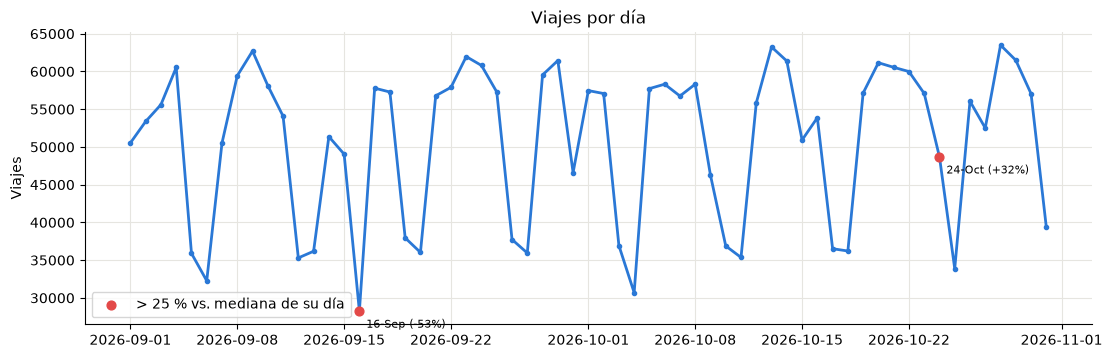

In [12]:
validos = viajes[dur.between(1, 180) & (viajes["Fecha_Hora_Retiro"] >= "2026-09-01")]
por_dia = validos.groupby("Fecha").size()
mediana_dow = por_dia.groupby(por_dia.index.day_of_week).transform("median")
desvio = por_dia / mediana_dow - 1

fig, ax = plt.subplots(figsize=(13, 3.8))
ax.plot(por_dia.index, por_dia, marker="o", markersize=3)
raros = desvio[desvio.abs() > 0.25]
ax.scatter(raros.index, por_dia[raros.index], color="#e34948", zorder=3, s=40, label="> 25 % vs. mediana de su día")
for d in raros.index:
    ax.annotate(f"{d:%d-%b} ({desvio[d]:+.0%})", (d, por_dia[d]), xytext=(5, -12), textcoords="offset points", fontsize=8)
ax.set(title="Viajes por día", ylabel="Viajes")
ax.legend()
plt.show()

Estaciones con mediana >= 20 eventos por día: 673
Estación-días prácticamente sin actividad (<= 2 eventos): 483 en 258 estaciones distintas
Estación 84: apagada 22 días, entre el 01-Sep y el 27-Oct


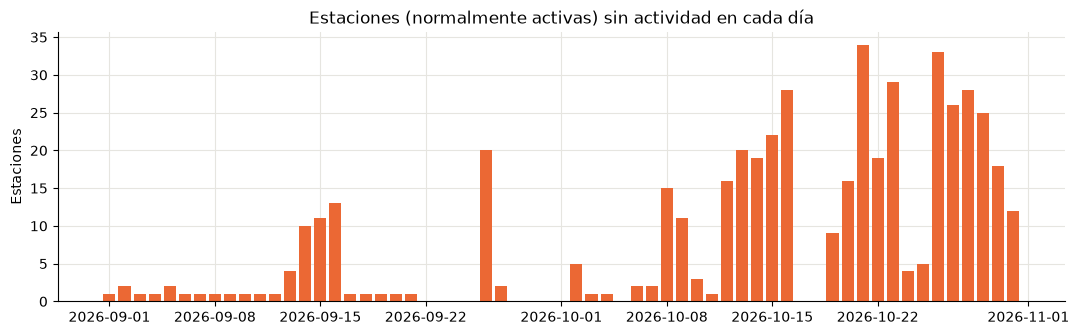

In [13]:
# Estaciones con mucho movimiento que de pronto tienen cero eventos en un día hábil = cierre o falla
eventos_dia = pd.concat([
    validos[["Fecha", "Ciclo_Estacion_Retiro"]].set_axis(["Fecha", "est"], axis=1),
    validos[["Fecha", "Ciclo_Estacion_Arribo"]].set_axis(["Fecha", "est"], axis=1),
]).groupby(["est", "Fecha"]).size().unstack(fill_value=0)
ocupadas = eventos_dia.index[eventos_dia.median(axis=1) >= 20]
apagadas = eventos_dia.loc[ocupadas] <= 2
print(f"Estaciones con mediana >= 20 eventos por día: {len(ocupadas)}")
print(f"Estación-días prácticamente sin actividad (<= 2 eventos): {apagadas.values.sum()} "
      f"en {apagadas.any(axis=1).sum()} estaciones distintas")
dias_84 = apagadas.columns[apagadas.loc[84]]
print(f"Estación 84: apagada {len(dias_84)} días, entre el {dias_84.min():%d-%b} y el {dias_84.max():%d-%b}")

fig, ax = plt.subplots(figsize=(13, 3.5))
ax.bar(apagadas.columns, apagadas.sum(), color="#eb6834")
ax.set(title="Estaciones (normalmente activas) sin actividad en cada día", ylabel="Estaciones")
plt.show()

In [14]:
dias_buenavista = apagadas.loc[[271, 266, 273, 264, 268, 176]]
print("Días en que alguna estación del nodo Buenavista estuvo apagada:")
print([f"{d:%d-%b}" for d in dias_buenavista.columns[dias_buenavista.any()]])

Días en que alguna estación del nodo Buenavista estuvo apagada:
['14-Sep', '15-Sep', '16-Sep', '27-Sep']


- **16-sep** (Día de la Independencia, miércoles) tiene la mitad de viajes de un miércoles normal,
  pero el EDA lo cuenta como día hábil en los promedios por hora y en la "oscilación intradía".
- **14 al 16-sep** el nodo Buenavista está prácticamente apagado; el cuaderno de Markov ya lo excluía, el EDA no.
- **Octubre tiene cierres rotativos:** desde el 8-oct, grupos de 10 a 34 estaciones se apagan 1–2 días
  hábiles cada una (parece una campaña de mantenimiento o cambio de equipo). En total ~250 estaciones
  distintas. Los promedios por estación de octubre están un poco subestimados y, si una estación del
  clúster se apaga, ese día no sirve para la cadena de Markov.
- **26-sep** (sábado) tiene 20 estaciones apagadas a la vez; **24-oct** (sábado) tiene 32 % más viajes de
  lo normal. Ambos son eventos puntuales de fin de semana.

In [15]:
hallazgos += [
    ("Feriado 16-sep", "−53 % de viajes; el EDA lo cuenta como día hábil", "Media",
     "Excluir FERIADOS de los promedios entre semana"),
    ("Cierre Buenavista", "14–16 sep sin actividad en el nodo 271/266/273/264/268/176", "Alta (para el clúster)",
     "Excluir CIERRE_BUENAVISTA en cualquier análisis del clúster"),
    ("Cierres rotativos en octubre", "~250 estaciones apagadas 1–2 días hábiles cada una (desde el 8-oct)", "Media",
     "Detectar estación-días apagados y excluirlos de promedios por estación y de la cadena de Markov"),
    ("Estación 84", f"Sin actividad {len(dias_84)} días (casi todo septiembre)", "Baja", "Excluir esos días para la 84"),
    ("26-sep y 24-oct", "20 estaciones apagadas un sábado / +32 % de viajes otro sábado", "Baja",
     "Solo afecta fines de semana; anotarlo"),
]

## 5. Consistencia de cada bicicleta
Si los datos están sanos, una bici no puede estar en dos viajes a la vez, y el siguiente viaje de una
bici debería salir de donde la dejaron. Cuando no es así, alguien la movió en camión (o se fue a taller).

In [16]:
b = viajes.dropna(subset=["Ciclo_Estacion_Retiro", "Ciclo_Estacion_Arribo"]).sort_values(["Bici", "Fecha_Hora_Retiro"])
g = b.groupby("Bici")
sig_retiro = g["Fecha_Hora_Retiro"].shift(-1)
sig_est = g["Ciclo_Estacion_Retiro"].shift(-1)
encimados = (sig_retiro < b["Fecha_Hora_Arribo"]).sum()
tiene_sig = sig_est.notna()
movida = tiene_sig & (sig_est != b["Ciclo_Estacion_Arribo"])

print(f"Bicis distintas: {b['Bici'].nunique():,}")
print(f"Viajes que empiezan antes de que la misma bici termine el anterior: {encimados}")
print(f"Pares de viajes consecutivos: {tiene_sig.sum():,} | la bici apareció en otra estación: {movida.sum():,} "
      f"({movida.sum() / tiene_sig.sum():.1%}) -> ~{movida.sum() / 61:,.0f} bicis movidas por día")

Bicis distintas: 6,584
Viajes que empiezan antes de que la misma bici termine el anterior: 0
Pares de viajes consecutivos: 3,091,734 | la bici apareció en otra estación: 251,157 (8.1%) -> ~4,117 bicis movidas por día


In [17]:
movidas = b[movida]
salida = movidas["Ciclo_Estacion_Arribo"].value_counts().rename("Sacadas_por_operacion")
entrada = sig_est[movida].astype(int).value_counts().rename("Metidas_por_operacion")
ops = pd.concat([salida, entrada], axis=1).fillna(0).astype(int)
ops["Neto_operacion_dia"] = ((ops["Metidas_por_operacion"] - ops["Sacadas_por_operacion"]) / 61).round(1)
ops.insert(0, "Estacion", ops.index.map(estaciones["Estacion"]))
print("Estaciones donde la operación saca más bicis por día:")
ops.sort_values("Neto_operacion_dia").head(8)

Estaciones donde la operación saca más bicis por día:


,Estacion,Sacadas_por_operacion,Metidas_por_operacion,Neto_operacion_dia
271,Jesus Garcia y Carlos J. Meneses,20980,8074,-211.6
266,Jesus Garcia y Carlos J. Meneses,8231,3120,-83.8
594,Xochicalco y Obrero Mundial,2669,25,-43.3
14,Av. Paseo de la Reforma y Rio de la Plata,3780,1573,-36.2
548,Doctor Mariano Azuela y Jose Antonio Alzate,3526,1737,-29.3
273,Luis Donaldo Colosio y Jesus Garcia,5125,3375,-28.7
29,Av. Paseo de la Reforma y Bucareli,2093,411,-27.6
217,Euler y Horacio,2198,557,-26.9


Ninguna bici está en dos viajes a la vez: la base es internamente consistente. El 8 % de "saltos"
no es un error, es el **rebalanceo real** (o mantenimiento), y se ve claramente en Buenavista: la
operación saca ~340 bicis diarias solo de la 271. Esto es lo que permite reconstruir el inventario
k(t) de cada estación, que es la variable que pide el paper y que Ecobici no publica.

In [18]:
hallazgos += [
    ("Bicis en dos viajes a la vez", "0 casos", "OK", "Ninguna"),
    ("Saltos de estación", "8.1 % de los viajes consecutivos (~4,100 bicis/día movidas por la operación)", "Info",
     "Usarlos para reconstruir el inventario y medir el rebalanceo real"),
]

## 6. Supuestos del EDA que conviene corregir

In [19]:
neto = validos.groupby("Ciclo_Estacion_Arribo").size().sub(validos.groupby("Ciclo_Estacion_Retiro").size(), fill_value=0)
print(f"Neto (arribos − retiros) de la 271 en el EDA: {neto.loc[271] / 61:+.0f} bicis/día")
print(f"Neto de la operación en la 271:                {ops.loc[271, 'Neto_operacion_dia']:+.0f} bicis/día")
print("La suma es ~0: el 'Neto' del EDA no es acumulación real, es lo que los camiones tienen que retirar.")

Neto (arribos − retiros) de la 271 en el EDA: +212 bicis/día
Neto de la operación en la 271:                -212 bicis/día
La suma es ~0: el 'Neto' del EDA no es acumulación real, es lo que los camiones tienen que retirar.


In [20]:
hallazgos += [
    ("Neto del EDA", "Arribos − retiros no es el cambio de inventario: la operación lo compensa a diario",
     "Media", "Interpretarlo como carga de rebalanceo, no como saturación acumulada"),
    ("Oscilación intradía", "Promedia días hábiles incluyendo el feriado y el cierre de Buenavista", "Media",
     "Recalcular sin FERIADOS / CIERRE_BUENAVISTA y dividir entre C del GBFS"),
    ("Nota de capacidad", "El EDA dice que C no está disponible", "Media", "Ya está: GBFS"),
]

## 7. Resumen

In [21]:
resumen = pd.DataFrame(hallazgos, columns=["Tema", "Resultado", "Gravedad", "Acción"])
with pd.option_context("display.max_colwidth", 120):
    display(resumen)

,Tema,Resultado,Gravedad,Acción
0,Partición por mes,Se corta por fecha de arribo; 0 viajes repetidos entre sep y oct,OK,Ninguna
1,Fin de periodo,Faltan los viajes que salen el 31-oct y llegan el 1-nov,Baja,Ignorar (sábado de madrugada)
2,Duplicados,0 exactos y 0 por llave (bici + hora de retiro),OK,Ninguna
3,Duraciones,"447 < 1 min, 1,385 > 3 h, 61 > 24 h (retiros desde febrero)",Media,El filtro 1 min–3 h del EDA es correcto para demanda
4,Edades,41 viajes con edad > 90 (el EDA solo cita las de 130),Baja,Poner como nulo > 90 en el perfil de usuarios
5,Género,2.5 % con género '?',Baja,Reportarlo como 'sin dato'
6,Horario,"Sin retiros de 1:00 a 4:59, consistente con la operación",OK,Ninguna
7,Capacidad C,"No está en el catálogo, pero sí en el GBFS para las 677 estaciones (3 a 75 puertos)",Alta,Usar datasetting.cargar_capacidades() en lugar de suponer C = 39
8,IDs dobles,12 estaciones como '271-272' son una sola estación grande; quedarse con el primer número es correcto,OK,Ninguna; usar la capacidad combinada del GBFS
9,Coordenadas,Las estaciones 21 y 22 tienen coordenadas idénticas en el catálogo -> 63 viajes con 0 km,Baja,Tomar coordenadas del GBFS


**Veredicto:** los datos de viajes están limpios para lo que se usan (sin duplicados, sin traslapes,
IDs consistentes con el catálogo y el GBFS). Lo que hay que corregir son supuestos del análisis: el
feriado, el cierre de Buenavista y los cierres rotativos de octubre en los promedios, la capacidad C
(ya disponible) y la lectura del "Neto" como saturación cuando en realidad es trabajo de los camiones.